***Imports***

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import operator
from pathlib import Path

 ***Carregar o dataset***

In [2]:
csv_base = Path.cwd().parent.parent.parent / "data" 
csv_path = csv_base / "dataset_completo.v2.csv"
df = pd.read_csv(csv_path, engine="pyarrow")

### Teste

In [ ]:
dfI = pd.read_csv('data/raw/On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_3.csv')

C:\Users\Henrique\AppData\Local\Temp\ipykernel_24184\686267732.py:1: DtypeWarning: Columns (77,84,85) have mixed types. Specify dtype option on import or set low_memory=False.
  dfI = pd.read_csv('data/raw/On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_3.csv')


In [ ]:
dfI['Origin'].head()

0    CLE
1    CLE
2    DCA
3    ORF
4    CLT
Name: Origin, dtype: object

In [ ]:
dfI['Origin'] = dfI['Origin'].astype('category')

In [ ]:
dfI['Origin'].head()

0    CLE
1    CLE
2    DCA
3    ORF
4    CLT
Name: Origin, dtype: category
Categories (361, object): ['ABE', 'ABI', 'ABQ', 'ABR', ..., 'XWA', 'YAK', 'YKM', 'YUM']

In [ ]:
dfI.shape

(564853, 110)

In [ ]:
dfI.drop(columns=['FlightDate','DOT_ID_Reporting_Airline','IATA_CODE_Reporting_Airline','Tail_Number','Flight_Number_Reporting_Airline'],inplace=True)
dfI.drop(columns=['OriginAirportSeqID','Origin','OriginCityName','OriginState','OriginStateName','OriginWac','DestAirportSeqID','Dest'],inplace=True)
dfI.drop(columns=['DestCityName','DestState','DestStateName','DestWac','DepTime','DepDelay','DepDelayMinutes','DepDel15','DepartureDelayGroups'],inplace=True)
dfI.drop(columns=['DepTimeBlk','TaxiOut','WheelsOff','WheelsOn','TaxiIn','ArrTime','ArrDelayMinutes','ArrDel15','ArrivalDelayGroups','ArrTimeBlk'],inplace=True)
dfI.drop(columns=['CancellationCode','ActualElapsedTime','AirTime','Flights','CarrierDelay','WeatherDelay','NASDelay','SecurityDelay'],inplace=True)
dfI.drop(columns=['LateAircraftDelay','FirstDepTime','TotalAddGTime','LongestAddGTime','DivAirportLandings','DivReachedDest','DivActualElapsedTime'],inplace=True)
dfI.drop(columns=['DivArrDelay','DivDistance','Div1Airport','Div1AirportID','Div1AirportSeqID','Div1WheelsOn','Div1TotalGTime'],inplace=True)
dfI.drop(columns=['Div1LongestGTime','Div1WheelsOff','Div1TailNum','Div2Airport','Div2AirportID','Div2AirportSeqID','Div2WheelsOn'],inplace=True)
dfI.drop(columns=['Div2TotalGTime','Div2LongestGTime','Div2WheelsOff','Div2TailNum','Div3Airport','Div3AirportID','Div3AirportSeqID'],inplace=True)
dfI.drop(columns=['Div3WheelsOn','Div3TotalGTime','Div3LongestGTime','Div3WheelsOff','Div3TailNum','Div4Airport','Div4AirportID'],inplace=True)
dfI.drop(columns=['Div4AirportSeqID','Div4WheelsOn','Div4TotalGTime','Div4LongestGTime','Div4WheelsOff','Div4TailNum','Div5Airport'],inplace=True)
dfI.drop(columns=['Div5AirportID','Div5AirportSeqID','Div5WheelsOn','Div5TotalGTime','Div5LongestGTime','Div5WheelsOff','Div5TailNum'],inplace=True)

In [ ]:
dfI.shape

(564853, 21)

### Fundir os dados mensais

In [ ]:
from pathlib import Path
import pandas as pd

pasta = Path("data")
arquivos = sorted(pasta.glob("raw/*.csv"))

if len(arquivos) != 24:
    raise ValueError(f"Esperava 24 arquivos, mas encontrei {len(arquivos)}.")

output_file = pasta / "dataset_completo.v2.csv"

# Garante que remove versões antigas incompletas se existirem
if output_file.exists():
    output_file.unlink()

for i, arquivo in enumerate(arquivos):
    print(f"A processar {i+1}/{len(arquivos)}: {arquivo.name}...")
    # Lê um único mês de cada vez
    df_temp = pd.read_csv(arquivo, low_memory=False)
    df_temp.drop(columns=['FlightDate','DOT_ID_Reporting_Airline','IATA_CODE_Reporting_Airline','Tail_Number','Flight_Number_Reporting_Airline'],inplace=True)
    df_temp.drop(columns=['OriginAirportSeqID','Origin','OriginCityName','OriginState','OriginStateName','OriginWac','DestAirportSeqID','Dest'],inplace=True)
    df_temp.drop(columns=['DestCityName','DestState','DestStateName','DestWac','DepTime','DepDelay','DepDelayMinutes','DepDel15','DepartureDelayGroups'],inplace=True)
    df_temp.drop(columns=['DepTimeBlk','TaxiOut','WheelsOff','WheelsOn','TaxiIn','ArrTime','ArrDelayMinutes','ArrDel15','ArrivalDelayGroups','ArrTimeBlk'],inplace=True)
    df_temp.drop(columns=['CancellationCode','ActualElapsedTime','AirTime','Flights','CarrierDelay','WeatherDelay','NASDelay','SecurityDelay'],inplace=True)
    df_temp.drop(columns=['LateAircraftDelay','FirstDepTime','TotalAddGTime','LongestAddGTime','DivAirportLandings','DivReachedDest','DivActualElapsedTime'],inplace=True)
    df_temp.drop(columns=['DivArrDelay','DivDistance','Div1Airport','Div1AirportID','Div1AirportSeqID','Div1WheelsOn','Div1TotalGTime'],inplace=True)
    df_temp.drop(columns=['Div1LongestGTime','Div1WheelsOff','Div1TailNum','Div2Airport','Div2AirportID','Div2AirportSeqID','Div2WheelsOn'],inplace=True)
    df_temp.drop(columns=['Div2TotalGTime','Div2LongestGTime','Div2WheelsOff','Div2TailNum','Div3Airport','Div3AirportID','Div3AirportSeqID'],inplace=True)
    df_temp.drop(columns=['Div3WheelsOn','Div3TotalGTime','Div3LongestGTime','Div3WheelsOff','Div3TailNum','Div4Airport','Div4AirportID'],inplace=True)
    df_temp.drop(columns=['Div4AirportSeqID','Div4WheelsOn','Div4TotalGTime','Div4LongestGTime','Div4WheelsOff','Div4TailNum','Div5Airport'],inplace=True)
    df_temp.drop(columns=['Div5AirportID','Div5AirportSeqID','Div5WheelsOn','Div5TotalGTime','Div5LongestGTime','Div5WheelsOff','Div5TailNum'],inplace=True)
    
    # Escreve logo no disco: apenas o primeiro ficheiro inclui o header
    df_temp.to_csv(
        output_file, 
        mode="a", 
        index=False, 
        header=(i == 0)
    )

print("Ficheiro dataset_completo.v2.csv gerado com sucesso!")

A processar 1/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_1.csv...
A processar 2/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_10.csv...
A processar 3/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_11.csv...
A processar 4/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_12.csv...
A processar 5/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_2.csv...
A processar 6/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_3.csv...
A processar 7/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_4.csv...
A processar 8/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_5.csv...
A processar 9/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_6.csv...
A processar 10/24: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2022_7.csv...
A processar 11/24: On_Time_Reporting_Carrier_On_Time_Performance_(

## Criação de um novo dataset com coluna target e limpo de outras formas

Criação da variável alvo

In [3]:
df["Target"] = np.select([df["ArrDelay"] < 15, df["ArrDelay"] <= 60], [1, 2], default=3)

In [ ]:
df.shape

In [89]:
df.columns

Index(['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek',
       'Reporting_Airline', 'OriginAirportID', 'OriginCityMarketID',
       'OriginStateFips', 'DestAirportID', 'DestCityMarketID', 'DestStateFips',
       'CRSDepTime', 'CRSArrTime', 'ArrDelay', 'Cancelled', 'Diverted',
       'CRSElapsedTime', 'Distance', 'DistanceGroup', 'Unnamed: 109',
       'Target'],
      dtype='object')

Eliminação da variavel do delay, agora que já temos o target, e de uma coluna com lixo

In [4]:
df.drop(columns=['ArrDelay','Unnamed: 109'],inplace=True)

In [91]:
df.isnull().sum()

Year                  0
Quarter               0
Month                 0
DayofMonth            0
DayOfWeek             0
Reporting_Airline     0
OriginAirportID       0
OriginCityMarketID    0
OriginStateFips       0
DestAirportID         0
DestCityMarketID      0
DestStateFips         0
CRSDepTime            0
CRSArrTime            0
Cancelled             0
Diverted              0
CRSElapsedTime        5
Distance              0
DistanceGroup         0
Target                0
dtype: int64

### Tratamento dos voos cancelados ou desviados

In [5]:
df['Cancelled'].value_counts()

Cancelled
0.0    13307795
1.0      269229
Name: count, dtype: int64

In [6]:
df['Diverted'].value_counts()

Diverted
0.0    13544646
1.0       32378
Name: count, dtype: int64

**Eliminação das amostras que correspondem a voos com cancelamentos ou devios** 

In [7]:
df = df[df['Cancelled']!=1]

In [8]:
df = df[df['Diverted']!=1]

In [9]:
df.shape

(13275417, 20)

Eliminação das colunas de cancelamento e desvio agora que não nos dão informação nenhuma

In [10]:
df.drop(columns=['Cancelled','Diverted'],inplace=True)

In [11]:
df.isnull().sum()

Year                  0
Quarter               0
Month                 0
DayofMonth            0
DayOfWeek             0
Reporting_Airline     0
OriginAirportID       0
OriginCityMarketID    0
OriginStateFips       0
DestAirportID         0
DestCityMarketID      0
DestStateFips         0
CRSDepTime            0
CRSArrTime            0
CRSElapsedTime        0
Distance              0
DistanceGroup         0
Target                0
dtype: int64

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13275417 entries, 0 to 13577023
Data columns (total 18 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Year                int64  
 1   Quarter             int64  
 2   Month               int64  
 3   DayofMonth          int64  
 4   DayOfWeek           int64  
 5   Reporting_Airline   object 
 6   OriginAirportID     int64  
 7   OriginCityMarketID  int64  
 8   OriginStateFips     int64  
 9   DestAirportID       int64  
 10  DestCityMarketID    int64  
 11  DestStateFips       int64  
 12  CRSDepTime          int64  
 13  CRSArrTime          int64  
 14  CRSElapsedTime      float64
 15  Distance            float64
 16  DistanceGroup       int64  
 17  Target              int32  
dtypes: float64(2), int32(1), int64(14), object(1)
memory usage: 1.8+ GB


### Transformações dos tipos das colunas

Transformar a coluna de distância e do elapsed time em inteiro, já que só tinhamos valores com .0 nesta coluna de floats

In [13]:
df['Distance'] = df['Distance'].astype("int64")

In [14]:
df['CRSElapsedTime'] = df['CRSElapsedTime'].astype("int64")

Transformar colunas que correspondem a IDs ou siglas de airlines em colunas categóricas de forma a que os modelos não assumam ordinalidade nos dados. 
Possivel de serem tratados doutra forma mais à frente para uso em modelos especificos

In [15]:
df['Reporting_Airline'] = df['Reporting_Airline'].astype("category")
df['OriginAirportID'] = df['OriginAirportID'].astype("category")
df['OriginCityMarketID'] = df['OriginCityMarketID'].astype("category")
df['OriginStateFips'] = df['OriginStateFips'].astype("category")
df['DestAirportID'] = df['DestAirportID'].astype("category")
df['DestCityMarketID'] = df['DestCityMarketID'].astype("category")
df['DestStateFips'] = df['DestStateFips'].astype("category")

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13275417 entries, 0 to 13577023
Data columns (total 18 columns):
 #   Column              Dtype   
---  ------              -----   
 0   Year                int64   
 1   Quarter             int64   
 2   Month               int64   
 3   DayofMonth          int64   
 4   DayOfWeek           int64   
 5   Reporting_Airline   category
 6   OriginAirportID     category
 7   OriginCityMarketID  category
 8   OriginStateFips     category
 9   DestAirportID       category
 10  DestCityMarketID    category
 11  DestStateFips       category
 12  CRSDepTime          int64   
 13  CRSArrTime          int64   
 14  CRSElapsedTime      int64   
 15  Distance            int64   
 16  DistanceGroup       int64   
 17  Target              int32   
dtypes: category(7), int32(1), int64(10)
memory usage: 1.3 GB


In [17]:
df.head()

,Year,Quarter,Month,DayofMonth,DayOfWeek,Reporting_Airline,OriginAirportID,OriginCityMarketID,OriginStateFips,DestAirportID,DestCityMarketID,DestStateFips,CRSDepTime,CRSArrTime,CRSElapsedTime,Distance,DistanceGroup,Target
0,2022,1,1,14,5,YX,11066,31066,39,11278,30852,51,1224,1352,88,323,2,1
1,2022,1,1,15,6,YX,11066,31066,39,11278,30852,51,1224,1352,88,323,2,1
2,2022,1,1,16,7,YX,11066,31066,39,11278,30852,51,1224,1352,88,323,2,1
3,2022,1,1,17,1,YX,11066,31066,39,11278,30852,51,1224,1352,88,323,2,1
4,2022,1,1,18,2,YX,11066,31066,39,11278,30852,51,1224,1352,88,323,2,1


### Engenharia de atributos

Transformar as colunas de inteiros hhmm em colunas de horas (hh) e minutos (mm)

In [18]:
df['CRSDepHour'] = df['CRSDepTime'] // 100
df['CRSDepMinute'] = df['CRSDepTime'] % 100

In [19]:
df.drop(columns=['CRSDepTime'],inplace=True)

In [20]:
df.head()

,Year,Quarter,Month,DayofMonth,DayOfWeek,Reporting_Airline,OriginAirportID,OriginCityMarketID,OriginStateFips,DestAirportID,DestCityMarketID,DestStateFips,CRSArrTime,CRSElapsedTime,Distance,DistanceGroup,Target,CRSDepHour,CRSDepMinute
0,2022,1,1,14,5,YX,11066,31066,39,11278,30852,51,1352,88,323,2,1,12,24
1,2022,1,1,15,6,YX,11066,31066,39,11278,30852,51,1352,88,323,2,1,12,24
2,2022,1,1,16,7,YX,11066,31066,39,11278,30852,51,1352,88,323,2,1,12,24
3,2022,1,1,17,1,YX,11066,31066,39,11278,30852,51,1352,88,323,2,1,12,24
4,2022,1,1,18,2,YX,11066,31066,39,11278,30852,51,1352,88,323,2,1,12,24


In [21]:
df['CRSArrHour'] = df['CRSArrTime'] // 100
df['CRSArrMinute'] = df['CRSArrTime'] % 100

In [22]:
df.drop(columns=['CRSArrTime'],inplace=True)

In [23]:
df.head()

,Year,Quarter,Month,DayofMonth,DayOfWeek,Reporting_Airline,OriginAirportID,OriginCityMarketID,OriginStateFips,DestAirportID,DestCityMarketID,DestStateFips,CRSElapsedTime,Distance,DistanceGroup,Target,CRSDepHour,CRSDepMinute,CRSArrHour,CRSArrMinute
0,2022,1,1,14,5,YX,11066,31066,39,11278,30852,51,88,323,2,1,12,24,13,52
1,2022,1,1,15,6,YX,11066,31066,39,11278,30852,51,88,323,2,1,12,24,13,52
2,2022,1,1,16,7,YX,11066,31066,39,11278,30852,51,88,323,2,1,12,24,13,52
3,2022,1,1,17,1,YX,11066,31066,39,11278,30852,51,88,323,2,1,12,24,13,52
4,2022,1,1,18,2,YX,11066,31066,39,11278,30852,51,88,323,2,1,12,24,13,52


In [24]:
target = df['Target']
df.drop(columns=['Target'],inplace=True)
df['Target'] = target


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13275417 entries, 0 to 13577023
Data columns (total 20 columns):
 #   Column              Dtype   
---  ------              -----   
 0   Year                int64   
 1   Quarter             int64   
 2   Month               int64   
 3   DayofMonth          int64   
 4   DayOfWeek           int64   
 5   Reporting_Airline   category
 6   OriginAirportID     category
 7   OriginCityMarketID  category
 8   OriginStateFips     category
 9   DestAirportID       category
 10  DestCityMarketID    category
 11  DestStateFips       category
 12  CRSElapsedTime      int64   
 13  Distance            int64   
 14  DistanceGroup       int64   
 15  CRSDepHour          int64   
 16  CRSDepMinute        int64   
 17  CRSArrHour          int64   
 18  CRSArrMinute        int64   
 19  Target              int32   
dtypes: category(7), int32(1), int64(12)
memory usage: 1.5 GB


In [26]:
df['MilesPerMinute'] = df['Distance'] / df['CRSElapsedTime']

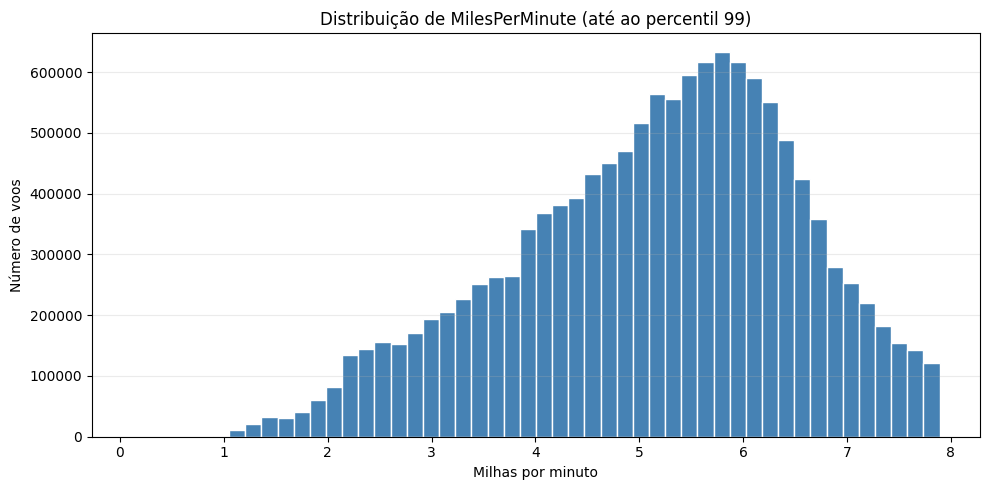

In [34]:
miles_per_minute = df["MilesPerMinute"]

miles_per_minute = miles_per_minute[np.isfinite(miles_per_minute) & (miles_per_minute > 0)]
limite_p99 = miles_per_minute.quantile(0.99)
valores_visiveis = miles_per_minute[miles_per_minute <= limite_p99]

plt.figure(figsize=(10, 5))
plt.hist(valores_visiveis, bins=50, color="steelblue", edgecolor="white")
plt.title("Distribuição de MilesPerMinute (até ao percentil 99)")
plt.xlabel("Milhas por minuto")
plt.ylabel("Número de voos")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Salvar o dataset

In [35]:
df.to_csv(csv_base/"dataset_completo_limpo.v2.csv",index=False)